# Experiment 1: zero-shot modality classification with BiomedCLIP on ROCOv2

Pipeline: clean dataframe (image ID, caption, modality) -> small validation subset -> load images ->
BiomedCLIP zero-shot -> compare with the manual modality annotation -> accuracy, macro-F1, confusion matrix.

**Ground truth** = the *manual* modality CUI in `valid_concepts_manual.csv` (6 classes). The 7th modality
(combined PET/CT) has no manual CUI, so those images are dropped here.

## 0. Configuration 

In [1]:
from pathlib import Path

# Folder holding the files downloaded from Zenodo (valid_images.zip, valid_captions.csv, ...)
DATA_DIR = Path("data/ROCOv2")
SPLIT = "valid"                 # "valid" -> use the validation split

SAMPLING = "balanced"           # "balanced": N_PER_CLASS per class | "proportional": N_TOTAL, natural class mix
N_PER_CLASS = 40                # balanced -> 6 classes x 40 = 240 images
N_TOTAL = 240                   # proportional only
SEED = 42
BATCH_SIZE = 32

MODEL_ID = "hf-hub:microsoft/BiomedCLIP-PubMedBERT_256-vit_base_patch16_224"
CONTEXT_LENGTH = 256
TEMPLATE = "this is a photo of "

OUT_DIR = Path("outputs")
OUT_DIR.mkdir(exist_ok=True)

## 1. Imports, device and model

In [2]:
import io
import zipfile

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from open_clip import create_model_from_pretrained, get_tokenizer
from PIL import Image
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score

device = torch.device("cuda" if torch.cuda.is_available()
                      else "mps" if getattr(torch.backends, "mps", None) and torch.backends.mps.is_available()
                      else "cpu")
print("Device:", device)

model, preprocess = create_model_from_pretrained(MODEL_ID)
tokenizer = get_tokenizer(MODEL_ID)
model = model.to(device).eval()
print("Model loaded.")

c:\Users\zakar\OneDrive\Bureau\AI4VIS\.venv\Lib\site-packages\transformers\utils\generic.py:441: FutureWarning: `torch.utils._pytree._register_pytree_node` is deprecated. Please use `torch.utils._pytree.register_pytree_node` instead.
  _torch_pytree._register_pytree_node(
c:\Users\zakar\OneDrive\Bureau\AI4VIS\.venv\Lib\site-packages\transformers\utils\generic.py:309: FutureWarning: `torch.utils._pytree._register_pytree_node` is deprecated. Please use `torch.utils._pytree.register_pytree_node` instead.
  _torch_pytree._register_pytree_node(
c:\Users\zakar\OneDrive\Bureau\AI4VIS\.venv\Lib\site-packages\timm\models\layers\__init__.py:49: FutureWarning: Importing from timm.models.layers is deprecated, please import via timm.layers
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.layers", FutureWarning)


Device: cpu


c:\Users\zakar\OneDrive\Bureau\AI4VIS\.venv\Lib\site-packages\huggingface_hub\file_download.py:949: FutureWarning: `resume_download` is deprecated and will be removed in version 1.0.0. Downloads always resume when possible. If you want to force a new download, use `force_download=True`.
  warnings.warn(
c:\Users\zakar\OneDrive\Bureau\AI4VIS\.venv\Lib\site-packages\transformers\utils\generic.py:309: FutureWarning: `torch.utils._pytree._register_pytree_node` is deprecated. Please use `torch.utils._pytree.register_pytree_node` instead.
  _torch_pytree._register_pytree_node(


Model loaded.


## 2. Clean dataframe: image ID, caption, modality

Each manual-concepts row holds semicolon-separated CUIs. Exactly one of them is a modality CUI
(CT `C0040405`, MRI `C0024485`, ultrasound `C0041618`, angiography `C0002978`, PET `C0032743`, X-ray `C1306645`).

In [3]:
CUI_TO_MODALITY = {
    "C0040405": "CT",
    "C0024485": "MRI",
    "C0041618": "ultrasound",
    "C0002978": "angiography",
    "C0032743": "PET",
    "C1306645": "X-ray",
}
CLASSES = list(CUI_TO_MODALITY.values())


def read_two_cols(path, names):
    """Read a 2-column ROCOv2 csv (header in the file); blank cells stay as empty strings."""
    df = pd.read_csv(path, header=0, usecols=[0, 1], dtype=str, keep_default_na=False)
    df.columns = names
    df["image_id"] = df["image_id"].str.replace(r"\.(jpe?g|png)$", "", regex=True, case=False)
    return df


captions = read_two_cols(DATA_DIR / f"{SPLIT}_captions.csv", ["image_id", "caption"])
manual = read_two_cols(DATA_DIR / f"{SPLIT}_concepts_manual.csv", ["image_id", "cuis"])


def modality_of(cuis):
    found = {CUI_TO_MODALITY[c] for c in cuis.split(";") if c in CUI_TO_MODALITY}
    return next(iter(found)) if len(found) == 1 else None      # none or ambiguous -> None


manual["modality"] = manual["cuis"].map(modality_of)

df = captions.merge(manual[["image_id", "modality"]], on="image_id", how="inner")
n_all = len(df)
df = df.dropna(subset=["modality"]).reset_index(drop=True)
print(f"{SPLIT}: {n_all} images with caption + concept row | "
      f"{len(df)} with a manual modality label | {n_all - len(df)} dropped (no manual modality, e.g. combined PET/CT)")
print("\nClass counts:")
print(df["modality"].value_counts().reindex(CLASSES))
df.head()

valid: 9904 images with caption + concept row | 9774 with a manual modality label | 130 dropped (no manual modality, e.g. combined PET/CT)

Class counts:
modality
CT             3673
MRI            1444
ultrasound     1528
angiography     421
PET              38
X-ray          2670
Name: count, dtype: int64


,image_id,caption,modality
0,ROCOv2_2023_valid_000001,Chest X-ray showing enlarged cardiac silhouett...,X-ray
1,ROCOv2_2023_valid_000002,Digital subtraction ureterogram with contrast ...,X-ray
2,ROCOv2_2023_valid_000003,Fifty-eight-year-old woman with 2 cancers: one...,X-ray
3,ROCOv2_2023_valid_000004,CT scan image for lung cancer.,CT
4,ROCOv2_2023_valid_000005,A giant retroperitoneal tumor.,CT


## 3. Select a small validation subset

`balanced` takes the same number of images per class, so macro-F1 is meaningful for rare classes such as PET.
(A random 200-image sample from the natural distribution would contain only ~1 PET image.)

In [4]:
if SAMPLING == "balanced":
    sub = pd.concat([df[df["modality"] == c].sample(n=min(N_PER_CLASS, (df["modality"] == c).sum()),
                                                     random_state=SEED) for c in CLASSES])
elif SAMPLING == "proportional":
    sub = df.sample(n=min(N_TOTAL, len(df)), random_state=SEED)
else:
    raise ValueError("SAMPLING must be 'balanced' or 'proportional'")

sub = sub.sample(frac=1, random_state=SEED).reset_index(drop=True)      # shuffle
print(f"Subset: {len(sub)} images")
print(sub["modality"].value_counts().reindex(CLASSES).to_string())

Subset: 238 images
modality
CT             40
MRI            40
ultrasound     40
angiography    40
PET            38
X-ray          40


## 4. Load the images (straight from the zip, no extraction needed)

Image batch: (238, 3, 224, 224)


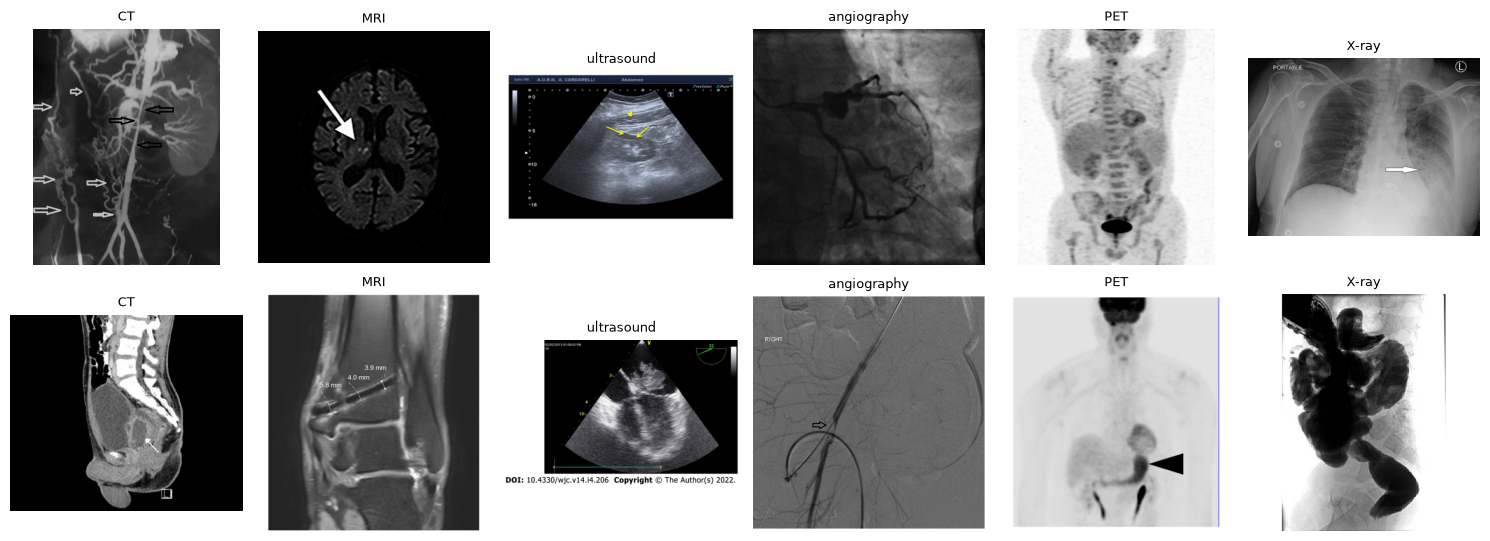

In [5]:
zf = zipfile.ZipFile(DATA_DIR / f"{SPLIT}_images.zip")
zip_index = {Path(n).stem: n for n in zf.namelist() if n.lower().endswith((".jpg", ".jpeg", ".png"))}

missing = [i for i in sub["image_id"] if i not in zip_index]
if len(missing) == len(sub):
    raise RuntimeError(f"No image IDs matched the zip. IDs look like {sub['image_id'][0]!r}, "
                       f"zip members look like {list(zip_index)[:3]}")
if missing:
    print(f"{len(missing)} images not found in zip, dropping them")
    sub = sub[~sub["image_id"].isin(missing)].reset_index(drop=True)


def load_pil(image_id):
    return Image.open(io.BytesIO(zf.read(zip_index[image_id]))).convert("RGB")


image_tensors = torch.stack([preprocess(load_pil(i)) for i in sub["image_id"]])
print("Image batch:", tuple(image_tensors.shape))

fig, axes = plt.subplots(2, 6, figsize=(15, 5.5))
for ax, cls in zip(axes.T, CLASSES):
    for a, (_, r) in zip(ax, sub[sub["modality"] == cls].head(2).iterrows()):
        a.imshow(load_pil(r["image_id"]), cmap="gray")
        a.set_title(cls, fontsize=9)
    for a in ax:
        a.axis("off")
plt.tight_layout()
plt.show()

## 5. Pass images and class prompts through BiomedCLIP

Text features are computed once for the six class prompts; images go through in batches.
The prediction is the class with the highest scaled cosine similarity (softmax gives the confidence).

In [6]:
@torch.no_grad()
def encode_prompts(labels, template=TEMPLATE):
    tok = tokenizer([template + l for l in labels], context_length=CONTEXT_LENGTH).to(device)
    return model.encode_text(tok, normalize=True).cpu()


@torch.no_grad()
def encode_images(tensors, batch_size=BATCH_SIZE):
    feats = []
    for i in range(0, len(tensors), batch_size):
        feats.append(model.encode_image(tensors[i:i + batch_size].to(device), normalize=True).cpu())
    return torch.cat(feats)


def predict(image_feats, text_feats):
    logits = model.logit_scale.exp().item() * image_feats @ text_feats.T
    probs = logits.softmax(dim=-1)
    conf, idx = probs.max(dim=-1)
    return idx.numpy(), conf.numpy(), probs.numpy()


image_feats = encode_images(image_tensors)                  # computed once, reused for every prompt set
text_feats = encode_prompts(CLASSES)
pred_idx, conf, probs = predict(image_feats, text_feats)

res = sub.copy()
res["pred"] = [CLASSES[i] for i in pred_idx]
res["confidence"] = conf
res["correct"] = res["pred"] == res["modality"]
res.to_csv(OUT_DIR / "exp1_predictions.csv", index=False)
print("Done.", len(res), "predictions saved to", OUT_DIR / "exp1_predictions.csv")

Done. 238 predictions saved to outputs\exp1_predictions.csv


## 6. Compare with the dataset annotations: accuracy, macro-F1, confusion matrix

Accuracy : 0.916   (majority-class baseline 0.168, uniform chance 0.167)
Macro-F1 : 0.917
Mean confidence: correct 0.972 | wrong 0.779

              precision    recall  f1-score   support

          CT      0.944     0.850     0.895        40
         MRI      1.000     0.950     0.974        40
  ultrasound      0.973     0.900     0.935        40
 angiography      0.800     1.000     0.889        40
         PET      0.971     0.895     0.932        38
       X-ray      0.857     0.900     0.878        40

    accuracy                          0.916       238
   macro avg      0.924     0.916     0.917       238
weighted avg      0.924     0.916     0.917       238



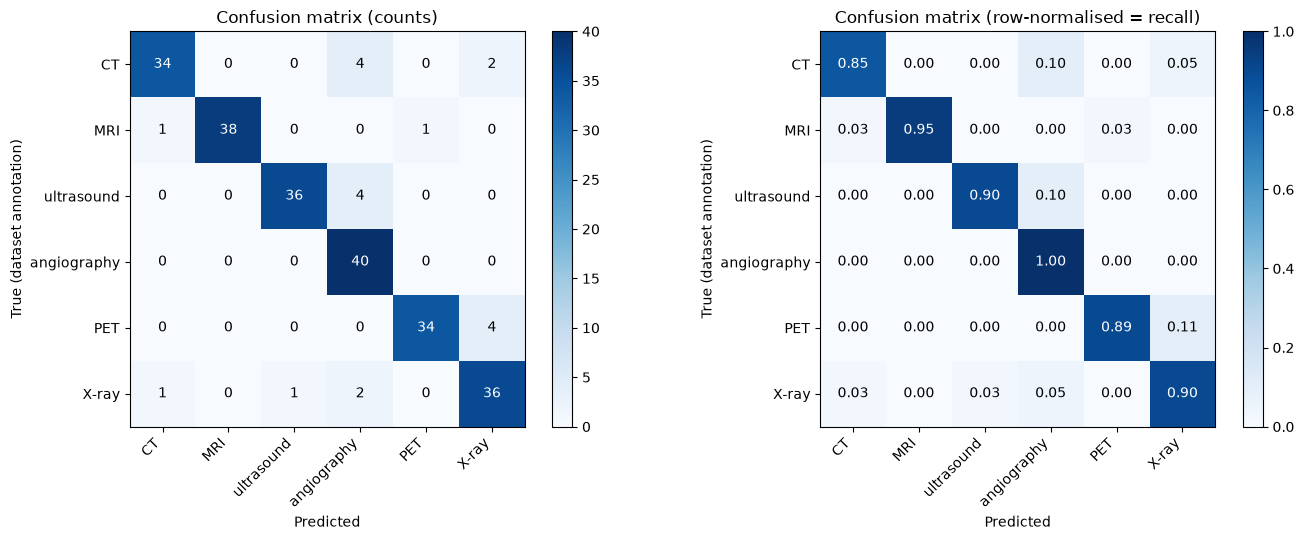

In [7]:
y_true, y_pred = res["modality"], res["pred"]

acc = accuracy_score(y_true, y_pred)
macro_f1 = f1_score(y_true, y_pred, labels=CLASSES, average="macro", zero_division=0)
majority = y_true.value_counts(normalize=True).max()

print(f"Accuracy : {acc:.3f}   (majority-class baseline {majority:.3f}, uniform chance {1/len(CLASSES):.3f})")
print(f"Macro-F1 : {macro_f1:.3f}")
print(f"Mean confidence: correct {res.loc[res.correct, 'confidence'].mean():.3f} | "
      f"wrong {res.loc[~res.correct, 'confidence'].mean():.3f}\n")
print(classification_report(y_true, y_pred, labels=CLASSES, zero_division=0, digits=3))

cm = confusion_matrix(y_true, y_pred, labels=CLASSES)
cm_norm = cm / cm.sum(axis=1, keepdims=True).clip(min=1)

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
for ax, mat, title, fmt in [(axes[0], cm, "Confusion matrix (counts)", "{:d}"),
                            (axes[1], cm_norm, "Confusion matrix (row-normalised = recall)", "{:.2f}")]:
    im = ax.imshow(mat, cmap="Blues")
    ax.set_xticks(range(len(CLASSES)), labels=CLASSES, rotation=45, ha="right")
    ax.set_yticks(range(len(CLASSES)), labels=CLASSES)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("True (dataset annotation)")
    ax.set_title(title)
    for r in range(len(CLASSES)):
        for c in range(len(CLASSES)):
            ax.text(c, r, fmt.format(mat[r, c]), ha="center", va="center",
                    color="white" if mat[r, c] > mat.max() * 0.6 else "black")
    fig.colorbar(im, ax=ax, fraction=0.046)
plt.tight_layout()
fig.savefig(OUT_DIR / "exp1_confusion_matrix.png", dpi=150)
plt.show()

## 7. Look at the errors

Check whether mistakes are model errors or label/caption problems (the ROCOv2 paper reports caption/label noise,
e.g. angiography vs plain X-ray).

In [8]:
errors = res[~res.correct]
pairs = (errors.groupby(["modality", "pred"]).size()
         .sort_values(ascending=False).rename("count").reset_index())
print("Most frequent confusions (true -> predicted):")
print(pairs.head(8).to_string(index=False))

pd.set_option("display.max_colwidth", 110)
print("\nMost confident mistakes:")
errors.sort_values("confidence", ascending=False)[["image_id", "modality", "pred", "confidence", "caption"]].head(10)

Most frequent confusions (true -> predicted):
  modality        pred  count
        CT angiography      4
ultrasound angiography      4
       PET       X-ray      4
        CT       X-ray      2
     X-ray angiography      2
       MRI         PET      1
       MRI          CT      1
     X-ray          CT      1

Most confident mistakes:


,image_id,modality,pred,confidence,caption
1,ROCOv2_2023_valid_008364,CT,angiography,0.999397,CTA image 1The image shows the narrowing of abdominal aorta distal to celiac artery and superior mesenteri...
159,ROCOv2_2023_valid_005393,CT,angiography,0.992181,"Computed tomography angiogram showing pseudoaneurysm, superficial femoral artery, and medial femoral circu..."
43,ROCOv2_2023_valid_009690,ultrasound,angiography,0.985402,Transesophageal echocardiography during surgery
230,ROCOv2_2023_valid_000510,CT,angiography,0.972499,Chest computed tomography angiography showing left superior vena cava draining abnormally into the left at...
73,ROCOv2_2023_valid_007184,X-ray,angiography,0.969178,Active transpapillary drainage of a pseudocyst located in the pancreatic tail.
186,ROCOv2_2023_valid_001565,X-ray,CT,0.959962,Right breast mammogram—mediolateral oblique incidence.
89,ROCOv2_2023_valid_002332,ultrasound,angiography,0.904396,Transoesophageal echocardiogram demonstrating posteriorly directed eccentric jet of severe mitral regurgit...
23,ROCOv2_2023_valid_003853,X-ray,ultrasound,0.861640,The acromion index was calculated by dividing the distance from line “a” to line “b” (GA) by the distance ...
69,ROCOv2_2023_valid_001385,PET,X-ray,0.830662,"Sestamibi scan, April 2015"
7,ROCOv2_2023_valid_003478,X-ray,angiography,0.742785,Contrast enema 6 weeks postoperatively demonstrating a well-configured colon and rectum without stenosis ...


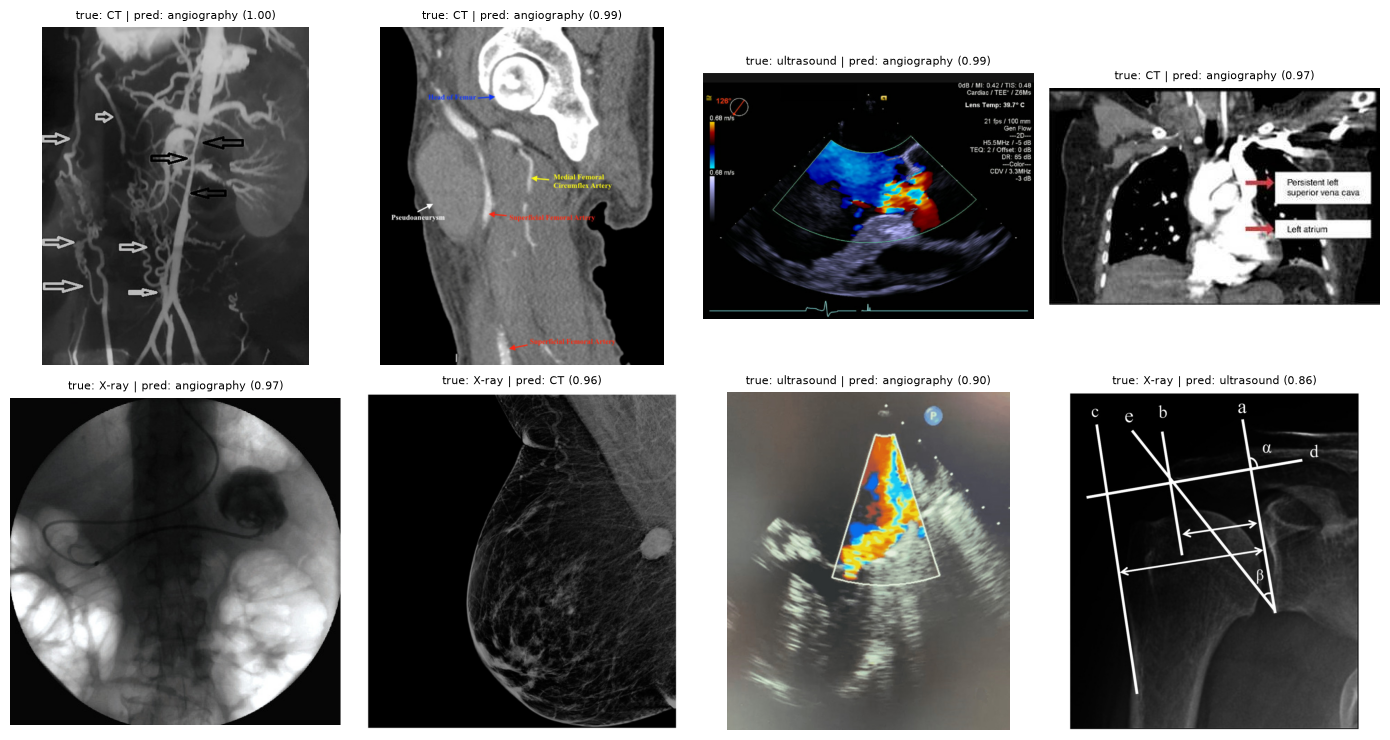

In [9]:
worst = errors.sort_values("confidence", ascending=False).head(8)
if len(worst):
    fig, axes = plt.subplots(2, 4, figsize=(14, 7.5))
    for ax, (_, r) in zip(axes.ravel(), worst.iterrows()):
        ax.imshow(load_pil(r["image_id"]), cmap="gray")
        ax.set_title(f"true: {r['modality']} | pred: {r['pred']} ({r['confidence']:.2f})", fontsize=8)
        ax.axis("off")
    for ax in axes.ravel()[len(worst):]:
        ax.axis("off")
    plt.tight_layout()
    plt.show()

## 8. Prompt sensitivity 



In [10]:
PROMPT_SETS = {
    "default (model-card style)": (TEMPLATE, CLASSES),
    "full names": (TEMPLATE, ["computed tomography (CT) scan", "magnetic resonance imaging (MRI) scan",
                              "ultrasound image", "angiography image", "PET scan", "X-ray radiograph"]),
    "radiology template": ("a radiology image: ", ["CT scan", "MRI scan", "ultrasound", "angiogram",
                                                   "PET scan", "X-ray"]),
}

rows = []
for name, (tmpl, labels) in PROMPT_SETS.items():
    p_idx, _, _ = predict(image_feats, encode_prompts(labels, tmpl))
    p = [CLASSES[i] for i in p_idx]
    rows.append({"prompt set": name,
                 "accuracy": accuracy_score(y_true, p),
                 "macro_F1": f1_score(y_true, p, labels=CLASSES, average="macro", zero_division=0)})
pd.DataFrame(rows).round(3)

,prompt set,accuracy,macro_F1
0,default (model-card style),0.916,0.917
1,full names,0.962,0.963
2,radiology template,0.954,0.955


20 wrong predictions in total, showing the 12 most confident


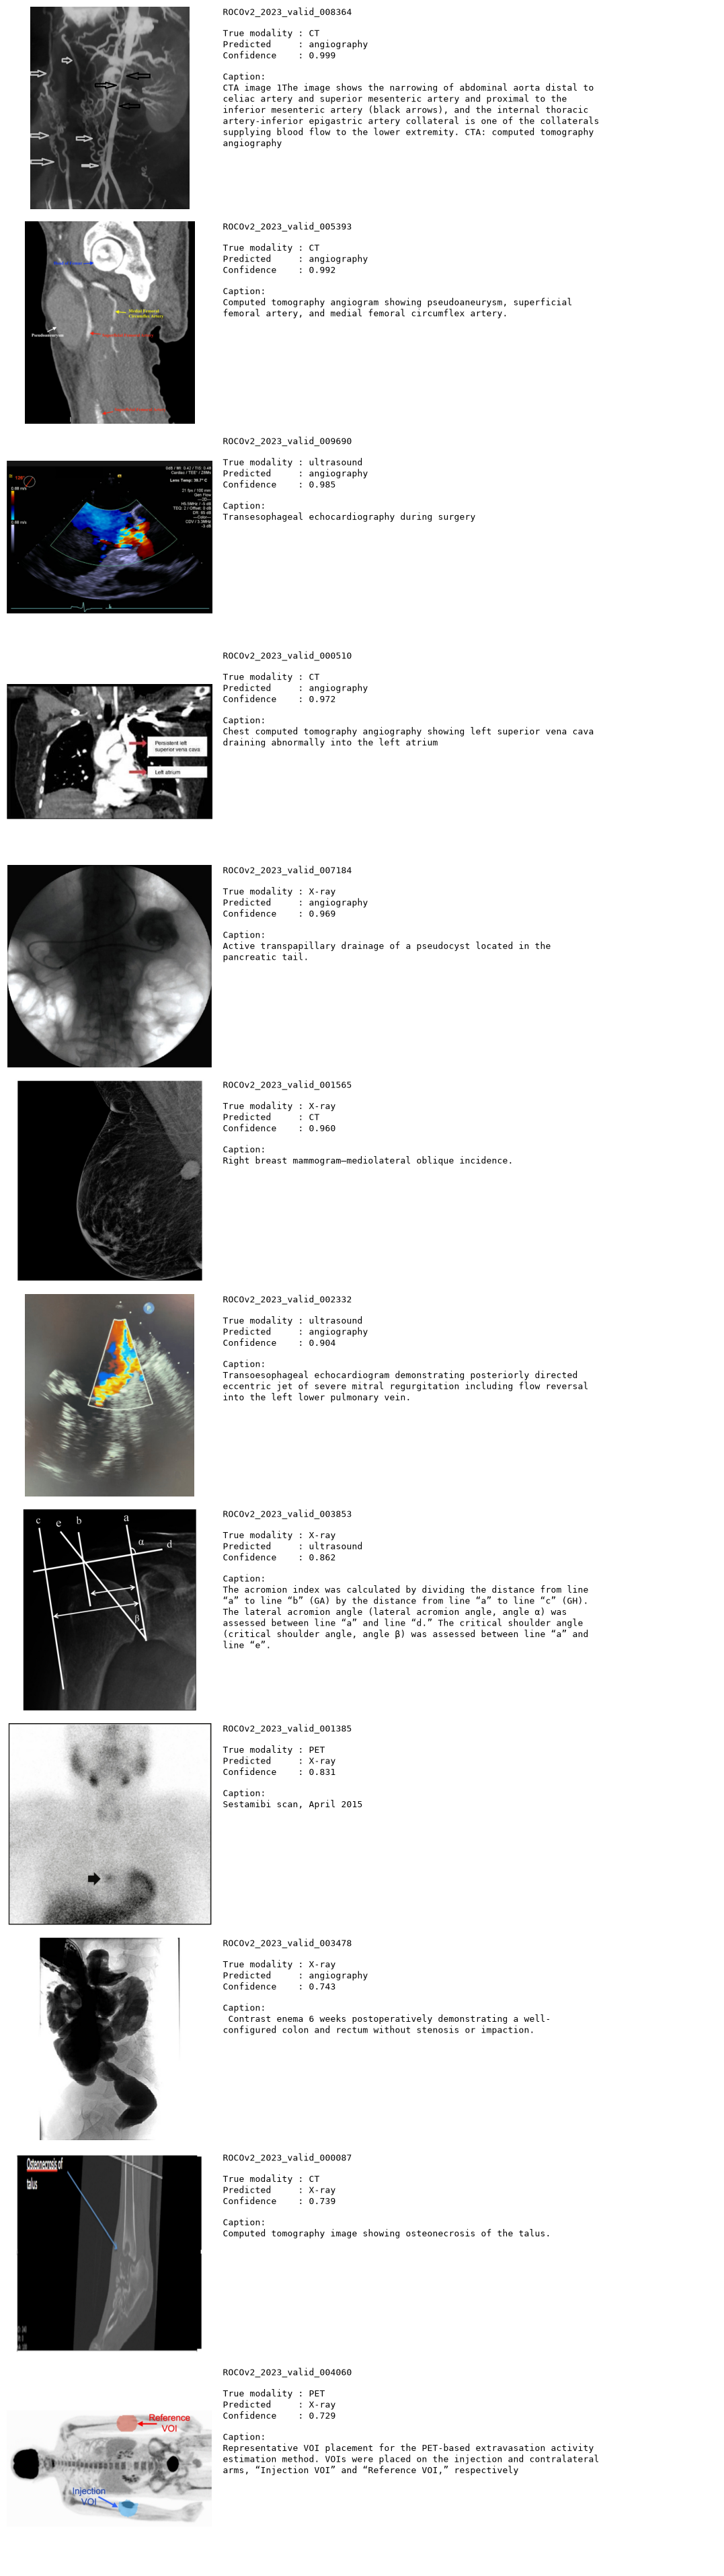

,image_id,modality,pred,confidence
0,ROCOv2_2023_valid_008364,CT,angiography,0.999
1,ROCOv2_2023_valid_005393,CT,angiography,0.992
2,ROCOv2_2023_valid_009690,ultrasound,angiography,0.985
3,ROCOv2_2023_valid_000510,CT,angiography,0.972
4,ROCOv2_2023_valid_007184,X-ray,angiography,0.969
5,ROCOv2_2023_valid_001565,X-ray,CT,0.960
6,ROCOv2_2023_valid_002332,ultrasound,angiography,0.904
7,ROCOv2_2023_valid_003853,X-ray,ultrasound,0.862
8,ROCOv2_2023_valid_001385,PET,X-ray,0.831
9,ROCOv2_2023_valid_003478,X-ray,angiography,0.743


In [11]:
import textwrap

N_EXAMPLES = 12   # change to anything between 10 and 15

# 1) wrong predictions only, 2) most confident first, 3) keep the top N
worst = (res[res["correct"] == False]
         .sort_values("confidence", ascending=False)
         .head(N_EXAMPLES)
         .reset_index(drop=True))
print(f"{(~res['correct']).sum()} wrong predictions in total, showing the {len(worst)} most confident")

# 4) one row per example: image on the left, details on the right
fig, axes = plt.subplots(len(worst), 2, figsize=(11, 3.2 * len(worst)),
                         gridspec_kw={"width_ratios": [1, 2.4]})
axes = np.atleast_2d(axes)

for (_, r), (ax_img, ax_txt) in zip(worst.iterrows(), axes):
    ax_img.imshow(load_pil(r["image_id"]), cmap="gray")
    ax_img.axis("off")

    caption = textwrap.fill(str(r["caption"]), width=70)
    if len(caption) > 420:
        caption = caption[:420].rstrip() + " ..."
    ax_txt.text(0, 1, f"{r['image_id']}\n\n"
                      f"True modality : {r['modality']}\n"
                      f"Predicted     : {r['pred']}\n"
                      f"Confidence    : {r['confidence']:.3f}\n\n"
                      f"Caption:\n{caption}",
                va="top", ha="left", fontsize=9, family="monospace",
                transform=ax_txt.transAxes)
    ax_txt.axis("off")

plt.tight_layout()
fig.savefig(OUT_DIR / "exp1_worst_errors.png", dpi=130)
plt.show()

# compact table of the same rows
worst[["image_id", "modality", "pred", "confidence"]].round(3)

In [13]:
# ---- Error analysis table (categories/explanations = manual reading of the 12 images shown) ----
ANALYSIS = {
    "ROCOv2_2023_valid_008364": ("Definition mismatch (CT angiography)",
        "Caption says CTA. ROCOv2 guideline labels CT angiography as CT; 'angiography' is only 2D X-ray vessel contrast."),
    "ROCOv2_2023_valid_005393": ("Definition mismatch (CT angiography)",
        "Caption says 'Computed tomography angiogram'. Labelled CT by guideline; the one-word prompt 'angiography' cannot encode this."),
    "ROCOv2_2023_valid_000510": ("Definition mismatch (CT angiography)",
        "Caption says 'Chest computed tomography angiography'. Same CTA-vs-angiography definition issue."),
    "ROCOv2_2023_valid_009690": ("Model error: colour Doppler",
        "Transesophageal echocardiography with red/blue flow overlay; model reads colour flow as vessel angiography."),
    "ROCOv2_2023_valid_002332": ("Model error: colour Doppler",
        "Transoesophageal echo with colour Doppler jet (photo of a screen); same Doppler-as-angiography confusion."),
    "ROCOv2_2023_valid_007184": ("Model error: non-vascular contrast study",
        "Fluoroscopic pseudocyst drainage; non-vascular contrast counts as X-ray, model reacts to contrast and wire."),
    "ROCOv2_2023_valid_003478": ("Model error: non-vascular contrast study",
        "Contrast enema (barium); correctly X-ray, model reads contrast-filled tube as angiography."),
    "ROCOv2_2023_valid_003853": ("Model error: overlays / unusual rendering",
        "Shoulder radiograph covered by measurement lines and labels, low contrast; predicted ultrasound."),
    "ROCOv2_2023_valid_000087": ("Model error: overlays / unusual rendering",
        "CT of talus osteonecrosis, dark panel with text/arrow overlay; predicted X-ray."),
    "ROCOv2_2023_valid_004060": ("Model error: overlays / unusual rendering",
        "Whole-body PET maximum-intensity projection with VOI labels; looks like a skeleton radiograph."),
    "ROCOv2_2023_valid_001565": ("Model error: mammography",
        "Mammogram (breast is only ~102 of ~21k X-ray images in ROCOv2); predicted CT."),
    "ROCOv2_2023_valid_001385": ("Possible label noise",
        "Caption 'Sestamibi scan' = nuclear medicine (scintigraphy/SPECT); guideline says that is not PET."),
}

cols = ["image_id", "modality", "pred", "confidence"]
table = (res[res["image_id"].isin(ANALYSIS)][cols]
         .rename(columns={"modality": "true_label", "pred": "predicted_label"}))
table["error_category"] = table["image_id"].map(lambda i: ANALYSIS[i][0])
table["explanation"] = table["image_id"].map(lambda i: ANALYSIS[i][1])
table["confidence"] = table["confidence"].round(3)
table = table.sort_values("confidence", ascending=False).reset_index(drop=True)

missing = set(ANALYSIS) - set(table["image_id"])
if missing:
    print(f"Note: {len(missing)} analysed IDs are not in `res` (different subset/seed?):", sorted(missing))

table.to_csv(OUT_DIR / "exp1_error_analysis.csv", index=False, encoding="utf-8-sig")   # opens cleanly in Excel

# also a markdown version for a report / README
md = ["| " + " | ".join(table.columns) + " |", "|" + "---|" * len(table.columns)]
md += ["| " + " | ".join(str(v).replace("|", "/") for v in row) + " |" for row in table.itertuples(index=False)]
(OUT_DIR / "exp1_error_analysis.md").write_text("\n".join(md), encoding="utf-8")

print("Saved:", OUT_DIR / "exp1_error_analysis.csv", "and", OUT_DIR / "exp1_error_analysis.md")
print("\nErrors per category:")
print(table["error_category"].value_counts().to_string())

pd.set_option("display.max_colwidth", 120)
table

Saved: outputs\exp1_error_analysis.csv and outputs\exp1_error_analysis.md

Errors per category:
error_category
Definition mismatch (CT angiography)         3
Model error: overlays / unusual rendering    3
Model error: colour Doppler                  2
Model error: non-vascular contrast study     2
Model error: mammography                     1
Possible label noise                         1


,image_id,true_label,predicted_label,confidence,error_category,explanation
0,ROCOv2_2023_valid_008364,CT,angiography,0.999,Definition mismatch (CT angiography),Caption says CTA. ROCOv2 guideline labels CT angiography as CT; 'angiography' is only 2D X-ray vessel contrast.
1,ROCOv2_2023_valid_005393,CT,angiography,0.992,Definition mismatch (CT angiography),Caption says 'Computed tomography angiogram'. Labelled CT by guideline; the one-word prompt 'angiography' cannot enc...
2,ROCOv2_2023_valid_009690,ultrasound,angiography,0.985,Model error: colour Doppler,Transesophageal echocardiography with red/blue flow overlay; model reads colour flow as vessel angiography.
3,ROCOv2_2023_valid_000510,CT,angiography,0.972,Definition mismatch (CT angiography),Caption says 'Chest computed tomography angiography'. Same CTA-vs-angiography definition issue.
4,ROCOv2_2023_valid_007184,X-ray,angiography,0.969,Model error: non-vascular contrast study,"Fluoroscopic pseudocyst drainage; non-vascular contrast counts as X-ray, model reacts to contrast and wire."
5,ROCOv2_2023_valid_001565,X-ray,CT,0.960,Model error: mammography,Mammogram (breast is only ~102 of ~21k X-ray images in ROCOv2); predicted CT.
6,ROCOv2_2023_valid_002332,ultrasound,angiography,0.904,Model error: colour Doppler,Transoesophageal echo with colour Doppler jet (photo of a screen); same Doppler-as-angiography confusion.
7,ROCOv2_2023_valid_003853,X-ray,ultrasound,0.862,Model error: overlays / unusual rendering,"Shoulder radiograph covered by measurement lines and labels, low contrast; predicted ultrasound."
8,ROCOv2_2023_valid_001385,PET,X-ray,0.831,Possible label noise,Caption 'Sestamibi scan' = nuclear medicine (scintigraphy/SPECT); guideline says that is not PET.
9,ROCOv2_2023_valid_003478,X-ray,angiography,0.743,Model error: non-vascular contrast study,"Contrast enema (barium); correctly X-ray, model reads contrast-filled tube as angiography."


In [14]:
np.savez(OUT_DIR / "exp1_image_embeddings.npz", ids=sub["image_id"].to_numpy(str), emb=image_feats.numpy())